---
# Hidden Markov Model - Optimal Transport
---

## Imports

In [4]:
# Standard library
import os
import glob
from pathlib import Path
from itertools import groupby
from functools import partial

# Utilities
from joblib import Parallel, delayed
from tqdm import tqdm

# Numerics - data
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
from matplotlib.colors import ListedColormap, BoundaryNorm
from cycler import cycler
import seaborn as sns

# Stats - signal
import scipy.stats as stats
from scipy.stats import zscore, spearmanr, mannwhitneyu, chi2
from scipy.signal import welch

# Statsmodels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.miscmodels.ordinal_model import OrderedModel

# Statistical annotations
from statannotations.Annotator import Annotator

# Machine learning
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.manifold import MDS
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import silhouette_score

# HMM
import jax
import jax.random as jr
import jax.numpy as jnp
from jax import vmap
from dynamax.hidden_markov_model import GaussianHMM
from dynamax.hidden_markov_model.models.gaussian_hmm import GaussianHMMEmissions, ParamsGaussianHMMEmissions
from dynamax.parameters import ParameterProperties
from dynamax.utils.bijectors import RealToPSDBijector
from dynamax.utils.distributions import InverseWishart
from dynamax.utils.utils import pytree_sum

# OT
import ot

## fMRI Utils

In [5]:
def load_fMRI(data_root, file_pattern):
    '''
    Load fMRI time series from a BIDS-like directory tree.
    '''
    data, subjects = [], []
    errors = 0

    subs = sorted(d for d in os.listdir(data_root) if os.path.isdir(os.path.join(data_root, d)) and d.startswith("sub-"))

    for sub in subs:
        sub_path = os.path.join(data_root, sub)
        sessions = sorted(s for s in os.listdir(sub_path) if os.path.isdir(os.path.join(sub_path, s)) and s.startswith("ses-"))

        for ses in sessions:
            func_dir = os.path.join(sub_path, ses, "func")
            if not os.path.isdir(func_dir):
                continue

            matched = sorted(glob.glob(os.path.join(func_dir, file_pattern)))

            for fp in matched:
                try:
                    data.append(pd.read_csv(fp, sep="\t").values)
                    subjects.append(f"{sub}_{ses}")
                except Exception as e:
                    print(f"Error loading {fp}: {e}")
                    errors += 1

    if data:
        print(f"Loaded {len(data)} subjects with shape {data[0].shape}")
    else:
        print("Loaded 0 subjects")

    if errors:
        print(f"Errors: {errors}")

    return np.asarray(data), np.asarray(subjects)


def zscore_fmri(fmri_data):
    '''
    Z-score each parcel across time.
    '''
    return np.asarray([zscore(subject_data, axis=1) for subject_data in fmri_data])


def compute_fc(signal):
    '''
    Compute the functional connectivity matrix.
    '''
    return np.corrcoef(signal)


def compute_pca(X, n_components=None):
    '''
    Fit PCA to a samples-by-features matrix.
    '''
    pca = PCA(n_components=n_components, svd_solver="full")
    projections = pca.fit_transform(X)
    return projections, pca.explained_variance_ratio_, pca.components_


def zscore_1d(x):
    '''
    Z-score a one-dimensional array while ignoring NaNs.
    '''
    x = np.asarray(x, dtype=float)
    mu, sigma = np.nanmean(x), np.nanstd(x)
    return np.full_like(x, np.nan) if sigma == 0 or np.isnan(sigma) else (x - mu) / sigma

## Plotting Utils

In [6]:
# General setting
colors = plt.cm.twilight(np.linspace(0.1, 1.0, 100))  # type: ignore
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

def plot_signals(x, dt=1, n_plot=10, title=None, figsize=(10,5)):
    '''
    Plot the trajectory of a (BOLD) signal over time. 
    '''
    x = x.T
    time_steps = x.shape[0]
    n_parcels = x.shape[1]

    # Generate the time array
    time = np.arange(0, time_steps * dt, dt)
    
    # Select random trajectories to plot
    random_indices = np.random.choice(n_parcels, size=n_plot, replace=False)
    selected_trajectories = x[:, random_indices]

    # Create the plot
    plt.figure(figsize=figsize)
    plt.plot(time, selected_trajectories, lw=1.5)
    if title is not None:
        plt.title(title, fontsize=14)
    plt.xlabel('Time', fontsize=13)
    plt.ylabel('x(t)', fontsize=13)
    plt.yticks(np.array([np.round(np.max(selected_trajectories), 0), 0, np.round(np.min(selected_trajectories), 0)]))

    # Customize the plot
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def plot_matrices(matrices, network_labels=None, network_names=None, titles=None, vminvmax=[[-1, 1]], center=None, cmap='RdBu_r',
                  figsize_per_matrix=(5, 4), sort=True, labels_for=None, dataset=None, label_pad_x=1.5, label_pad_y=1.5,
                  label_size=3.0, x_label_shift=0.0, y_label_shift=0.0, axes=None):
    '''
    Plot one or more matrices (FC) with optional network labels.
    '''
    if dataset is not None:
        network_labels = dataset.network_labels
        network_names = dataset.network_names

    num_matrices = len(matrices)

    # Create axes
    if axes is None:
        fig, axes = plt.subplots(1, num_matrices, figsize=(figsize_per_matrix[0] * num_matrices, figsize_per_matrix[1]),
                                 constrained_layout=True)
        if num_matrices == 1:
            axes = [axes]
    else:
        if num_matrices == 1:
            axes = [axes] if not isinstance(axes, (list, tuple, np.ndarray)) else list(np.ravel(axes))
        else:
            axes = list(np.ravel(axes))

    labels_available = (network_labels is not None) and (network_names is not None)

    # Select matrices with labels
    if labels_for is None:
        label_mask = [True] * num_matrices
    else:
        if isinstance(labels_for, (list, tuple)) and len(labels_for) == num_matrices and all(isinstance(x, (bool, np.bool_)) for x in labels_for):
            label_mask = list(labels_for)
        else:
            label_mask = [False] * num_matrices
            for idx in labels_for:
                label_mask[int(idx)] = True

    tick_positions, label_positions, tick_labels = [], [], []

    # Prepare network labels
    if labels_available:
        network_labels = np.array(network_labels)
        network_names = list(network_names)  # type: ignore

        if sort:
            _, sorted_labels = np.unique(network_labels, return_inverse=True)
            sorted_indices = np.argsort(sorted_labels, kind='stable')
            labels_sorted = sorted_labels[sorted_indices]
        else:
            sorted_indices = np.arange(len(network_labels))
            labels_sorted = network_labels

        prev_label = labels_sorted[0]
        start = 0
        tick_positions.append(0)

        for j, label in enumerate(labels_sorted):
            if label != prev_label:
                tick_positions.append(j)
                label_positions.append((start + j) / 2)
                tick_labels.append(network_names[prev_label])
                start = j
                prev_label = label

        tick_positions.append(len(labels_sorted))
        label_positions.append((start + len(labels_sorted)) / 2)
        tick_labels.append(network_names[prev_label])
    else:
        sorted_indices = None

    tick_positions = sorted(list(set(tick_positions)))
    label_fontsize = max(6, min(12, figsize_per_matrix[0] * label_size))

    # Plot matrices
    for i, (matrix, ax) in enumerate(zip(matrices, axes)):
        if labels_available and sort:
            mat_to_plot = matrix[np.ix_(sorted_indices, sorted_indices)]  # type: ignore
        else:
            mat_to_plot = matrix

        vmin = vminvmax[i][0]
        vmax = vminvmax[i][1]
        heatmap = sns.heatmap(mat_to_plot, ax=ax, cmap=cmap, center=center, vmin=vmin, vmax=vmax, square=True,
                              xticklabels=False, yticklabels=False, cbar=True, cbar_kws={'shrink': 1, 'pad': 0.05})

        cbar = heatmap.collections[0].colorbar
        if cbar:
            if np.min(mat_to_plot) <= 0:
                cbar.set_ticks([vmin, 0, vmax])
                cbar.set_ticklabels([f"{vmin:.1f}", "0", f"{vmax:.1f}"])
            else:
                cbar.set_ticks([vmin, vmax])
                cbar.set_ticklabels([f"{vmin:.1f}", f"{vmax:.1f}"])

            cbar.outline.set_edgecolor('black')  # type: ignore
            cbar.outline.set_linewidth(0.5)  # type: ignore
            cbar.ax.tick_params(labelsize=10)

        # Add network labels
        if labels_available and label_mask[i]:
            ax.set_xticks(tick_positions)
            ax.set_yticks(tick_positions)
            ax.set_xticklabels([])
            ax.set_yticklabels([])

            for pos, label in zip(label_positions, tick_labels):
                ax.text(pos + x_label_shift, ax.get_ylim()[0] + label_pad_x, label, ha='center', va='top',
                        fontsize=label_fontsize, rotation=90)
                ax.text(ax.get_xlim()[0] - label_pad_y, pos + y_label_shift, label, ha='right', va='center',
                        fontsize=label_fontsize)

        ax.tick_params(axis='both', length=3, width=0.8, labelsize=10)

        if titles and i < len(titles):
            ax.set_title(titles[i], fontsize=14)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('black')
            spine.set_linewidth(0.5)


def plot_cv_model_selection(df_cv, n_splits=5, figsize=(8, 5)):
    '''
    Plot held-out HMM log-likelihood across model orders and PCA dimensionalities.
    '''
    summary = df_cv.groupby(["n_components", "n_states"], as_index=False).agg(
        mean_ll=("ll_val_per_subject", "mean"), sd_ll=("ll_val_per_subject", "std")
    )
    summary["se_ll"] = summary["sd_ll"] / np.sqrt(n_splits)

    m_values = np.sort(summary["n_components"].unique())
    colors = plt.cm.twilight(np.linspace(0.12, 0.82, len(m_values)))

    fig, axes = plt.subplots(2, 3, figsize=figsize, constrained_layout=True)
    axes = np.ravel(axes)

    for i, M in enumerate(m_values):
        ax = axes[i]
        d = summary[summary["n_components"] == M].sort_values("n_states")

        ax.errorbar(d["n_states"], d["mean_ll"], yerr=d["se_ll"], marker="o", markersize=4.5,
                    linewidth=1.8, capsize=3, color=colors[i])
        ax.set_title(f"M = {int(M)}")
        ax.set_xticks([2, 4, 6, 8])
        ax.set_xlabel("K" if i >= 3 else "")
        ax.set_ylabel("Held-out log-likelihood" if i % 3 == 0 else "")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    for ax in axes[len(m_values):]:
        ax.axis("off")

    return fig, axes


def plot_state_means(means, network_labels, network_names, sort=True, cmap="RdBu_r", figsize=(12, 4)):
    '''
    Plot mean BOLD activity for each state grouped by network.
    '''
    means = np.asarray(means, dtype=float)
    network_labels = np.asarray(network_labels)
    network_names = np.asarray(network_names)

    n_states, n_parcels = means.shape

    if len(network_labels) != n_parcels:
        raise ValueError("network_labels and means have incompatible dimensions")

    if sort:
        order = np.argsort(network_labels, kind="stable")
        means_plot = means[:, order]
        labels_plot = network_labels[order]
    else:
        means_plot = means
        labels_plot = network_labels

    boundaries = np.r_[0, np.where(np.diff(labels_plot) != 0)[0] + 1, n_parcels]
    start_inds = boundaries[:-1]
    end_inds = boundaries[1:] - 1
    tick_positions = (start_inds + end_inds) / 2
    tick_labels = [network_names[labels_plot[i]] for i in start_inds]

    vmax = np.nanmax(np.abs(means_plot))

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(means_plot, aspect="auto", cmap=cmap, vmin=-vmax, vmax=vmax)
    fig.colorbar(im, ax=ax, label="Mean BOLD activity")

    for boundary in boundaries[1:-1]:
        ax.axvline(boundary - 0.5, color="black", lw=1)

    ax.set_xticks(tick_positions)
    ax.set_yticks(np.arange(n_states))
    ax.set_xticklabels(tick_labels)
    ax.set_xlabel("Resting-State Network")
    ax.set_ylabel("State")

    return fig, ax

## Global

In [7]:
# fMRI data
DATA_ROOT = Path("/readonly/insights/bids/MS/derivatives/xcp_d")
FILE_PATTERN = "*_space-fsLR_seg-4S156Parcels*_stat-mean_timeseries.tsv"

# Project directories
PROJECT_DIR = Path("/home/taffarello/codes/hmm_ot_project")
DATA_DIR = PROJECT_DIR / "data"
MAIN_DATA_DIR = DATA_DIR / "main"

for path in [DATA_DIR, MAIN_DATA_DIR]:
    path.mkdir(parents=True, exist_ok=True)

# Global parameters
TR = 1.5
T_PER_SUBJ = 240
N_PARCELS = 100
FS = 1.0 / TR

## Load Data

In [14]:
# Load fMRI data
data, subjects = load_fMRI(DATA_ROOT, FILE_PATTERN)

# Prepare cortical BOLD data
bold_all = data.transpose(0, 2, 1)[:, :N_PARCELS, :]
bold_zsc = zscore_fmri(bold_all)

n_subjects, n_parcels, n_time = bold_zsc.shape

if n_parcels != N_PARCELS or n_time != T_PER_SUBJ:
    raise ValueError(f"Unexpected BOLD shape: {bold_all.shape}")

# Load phenotype data
df_sel = pd.read_csv(DATA_DIR / "sel_features.csv", index_col="participant_id")

missing_features = [s for s in subjects if s not in df_sel.index]
if missing_features:
    raise ValueError(f"Missing features for {len(missing_features)} subjects: {missing_features[:10]}")

df_sel = df_sel.loc[subjects].copy()

# Load and align QC time series
qc_timeseries = pd.read_csv(DATA_DIR / "qc_timeseries.csv")
qc = qc_timeseries.set_index(["participant_id", "timepoint"])
fd = qc["FD"].unstack("timepoint").loc[subjects].to_numpy(dtype=float)
dvars = qc["DVARS"].unstack("timepoint").loc[subjects].to_numpy(dtype=float)

if fd.shape != (n_subjects, n_time) or dvars.shape != (n_subjects, n_time):
    raise ValueError("QC time series are not aligned with BOLD data")

# Load atlas data
parcel_names = np.load(DATA_DIR / "parcel_names.npy")
network_labels = np.load(DATA_DIR / "network_labels.npy")
network_names = np.load(DATA_DIR / "network_names.npy")

Loaded 217 subjects with shape (240, 156)


## Analysis

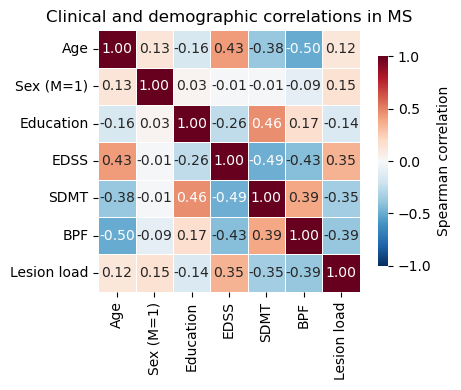

In [25]:
# Clinical and demographic correlations in MS
df_corr = df_sel.copy()

sex_map = {"F": 0, "M": 1}
df_corr["sex_num"] = df_corr["sex"].astype(str).str.strip().map(sex_map)

corr_features = ["age", "sex_num", "education", "EDSS", "SDMT", "BPF", "lesion_load"]
corr_labels = ["Age", "Sex (M=1)", "Education", "EDSS", "SDMT", "BPF", "Lesion load"]

df_ms = df_corr.loc[df_corr["group"].astype(str).str.upper().eq("MS"), corr_features].apply(pd.to_numeric, errors="coerce")

corr_ms = df_ms.corr(method="spearman")
corr_ms.index = corr_labels
corr_ms.columns = corr_labels

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr_ms, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "Spearman correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Clinical and demographic correlations in MS")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

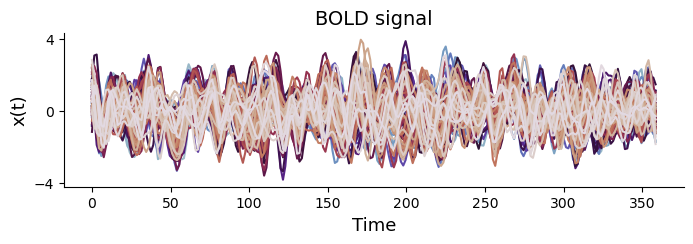

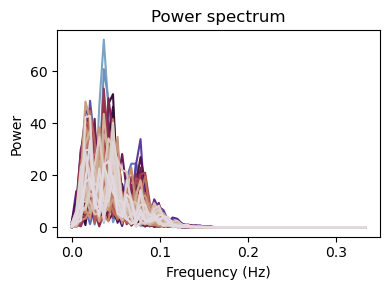

In [26]:
# Split by group
groups = df_sel["group"].astype(str).str.upper().to_numpy()
ms_mask = groups == "MS"
hc_mask = groups == "HC"

bold_ms = bold_zsc[ms_mask]
bold_hc = bold_zsc[hc_mask]

# Example BOLD signal
ms_idx = 0
plot_signals(bold_ms[ms_idx], dt=TR, n_plot=N_PARCELS, title="BOLD signal", figsize=(8, 2))
plt.show()

# Power spectrum for an example subject
signal = bold_ms[ms_idx]
frequencies, power_spectrum = welch(signal, fs=FS, axis=1, nperseg=128)

plt.figure(figsize=(4, 3))
for i in range(signal.shape[0]):
    plt.plot(frequencies, power_spectrum[i], )

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.title("Power spectrum")
plt.tight_layout()
plt.show()

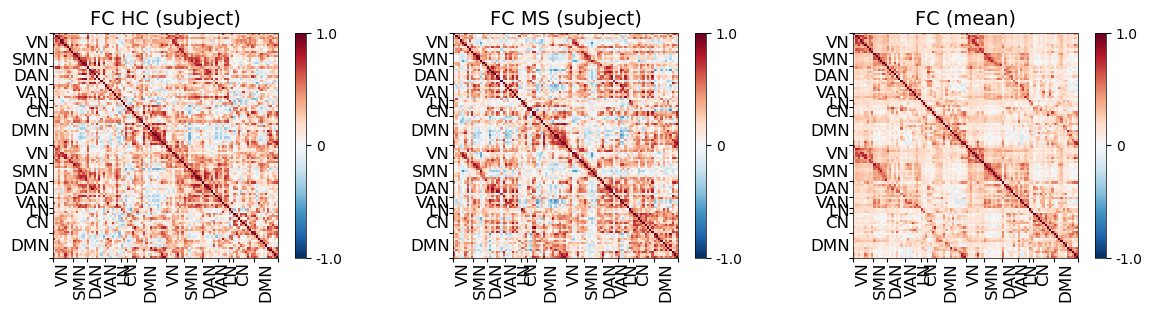

In [27]:
# Compute subject-level static FC
fcs_all = np.asarray([compute_fc(signal) for signal in bold_zsc])
fcs_ms = fcs_all[ms_mask]
fcs_hc = fcs_all[hc_mask]

# Group-averaged FC
fc_mean = fcs_all.mean(axis=0)
fc_mean_ms = fcs_ms.mean(axis=0)
fc_mean_hc = fcs_hc.mean(axis=0)

# Plot example FC matrices
plot_matrices([fcs_hc[0], fcs_ms[0], fc_mean], network_labels=network_labels, network_names=network_names,
              titles=["FC HC (subject)", "FC MS (subject)", "FC (mean)"], vminvmax=[[-1, 1], [-1, 1], [-1, 1]],
              cmap="RdBu_r", figsize_per_matrix=(4, 3), sort=False)
plt.show()

np.save(DATA_DIR / "fcs_all.npy", fcs_all)

# HMM

## HMM Utils

In [28]:
class ZeroMeanGaussianHMMEmissions(GaussianHMMEmissions):
    def __init__(self, num_states, emission_dim, emission_prior_scale=1e-4,
                 emission_prior_extra_df=0.1, init_jitter=1e-4):

        super().__init__(
            num_states=num_states,
            emission_dim=emission_dim,
            emission_prior_mean=0.0,
            emission_prior_concentration=1e-4,
            emission_prior_scale=emission_prior_scale,
            emission_prior_extra_df=emission_prior_extra_df,
        )

        self.init_jitter = float(init_jitter)

    def initialize(self, key=jr.PRNGKey(0), method="prior", emission_means=None,
                   emission_covariances=None, emissions=None):

        if emission_means is not None and not np.allclose(np.asarray(emission_means), 0.0):
            raise ValueError("ZeroMeanGaussianHMM requires emission_means = 0")

        if emission_covariances is not None:
            covs = jnp.asarray(emission_covariances)

        elif method.lower() == "kmeans":
            if emissions is None:
                raise ValueError("emissions are required for k-means initialization")

            X = np.asarray(emissions).reshape(-1, self.emission_dim)
            seed = int(jr.randint(key, (), 0, 2**31 - 1))
            labels = KMeans(n_clusters=self.num_states, n_init=10, random_state=seed).fit_predict(X)

            # Global uncentred second moment, used as fallback
            global_cov = X.T @ X / X.shape[0]
            eye = np.eye(self.emission_dim)
            covs = []

            for k in range(self.num_states):
                Xk = X[labels == k]
                cov_k = Xk.T @ Xk / len(Xk) if len(Xk) > self.emission_dim else global_cov.copy()
                cov_k = 0.5 * (cov_k + cov_k.T)
                cov_k += self.init_jitter * eye
                covs.append(cov_k)

            covs = jnp.asarray(covs)

        elif method.lower() == "prior":
            prior = InverseWishart(self.emission_prior_df, self.emission_prior_scale)
            covs = prior.sample(seed=key, sample_shape=(self.num_states,))

        else:
            raise ValueError(f"Unknown initialization method: {method}")

        params = ParamsGaussianHMMEmissions(
            means=jnp.zeros((self.num_states, self.emission_dim)),
            covs=covs,
        )

        props = ParamsGaussianHMMEmissions(
            means=ParameterProperties(trainable=False),
            covs=ParameterProperties(constrainer=RealToPSDBijector()),
        )

        return params, props

    def log_prior(self, params):
        prior = InverseWishart(self.emission_prior_df, self.emission_prior_scale)
        return prior.log_prob(params.covs).sum()

    def m_step(self, params, props, batch_stats, m_step_state):
        stats = pytree_sum(batch_stats, axis=0)
        sum_w = stats["sum_w"]
        sum_xxT = stats["sum_xxT"]

        # Fixed-mean posterior
        post_df = self.emission_prior_df + sum_w
        post_scale = self.emission_prior_scale[None, :, :] + sum_xxT
        covs = post_scale / (post_df[:, None, None] + self.emission_dim + 1)
        covs = 0.5 * (covs + jnp.swapaxes(covs, -1, -2))

        params = params._replace(means=jnp.zeros_like(params.means), covs=covs)
        return params, m_step_state


class ZeroMeanGaussianHMM(GaussianHMM):
    def __init__(self, num_states, emission_dim, initial_probs_concentration=1.1,
                 transition_matrix_concentration=1.1, transition_matrix_stickiness=0.0,
                 emission_prior_scale=1e-4, emission_prior_extra_df=0.1, init_jitter=1e-4):

        super().__init__(
            num_states=num_states,
            emission_dim=emission_dim,
            initial_probs_concentration=initial_probs_concentration,
            transition_matrix_concentration=transition_matrix_concentration,
            transition_matrix_stickiness=transition_matrix_stickiness,
            emission_prior_mean=0.0,
            emission_prior_concentration=1e-4,
            emission_prior_scale=emission_prior_scale,
            emission_prior_extra_df=emission_prior_extra_df,
        )

        self.emission_component = ZeroMeanGaussianHMMEmissions(
            num_states=num_states,
            emission_dim=emission_dim,
            emission_prior_scale=emission_prior_scale,
            emission_prior_extra_df=emission_prior_extra_df,
            init_jitter=init_jitter,
        )


def num_params_gaussian_hmm(K, D, zero_mean=True):
    '''
    Number of free parameters in a K-state Gaussian HMM with D-dimensional full-covariance emissions.
    '''
    init_probs = K - 1
    transitions = K * (K - 1)
    covariances = K * D * (D + 1) // 2
    means = 0 if zero_mean else K * D

    return init_probs + transitions + covariances + means


def hmm_data_ll(hmm, params, emissions):
    '''
    Marginal data log-likelihood summed over independent subject sequences.
    '''
    seq_lls = vmap(partial(hmm.marginal_log_prob, params))(emissions)
    return float(seq_lls.sum())


def fit_hmm_restarts(emissions, n_states, n_iter=300, n_restarts=20, random_state=None, zero_mean=True):
    '''
    Fit a full-covariance Gaussian HMM with multiple restarts.
    '''
    emission_dim = emissions.shape[2]
    rng = np.random.default_rng(random_state)

    best_ll = -np.inf
    best_hmm = best_params = best_props = best_lls = best_seed = None
    rows = []

    for i in range(n_restarts):
        seed = int(rng.integers(0, int(1e6)))
        key = jax.random.PRNGKey(seed)

        hmm = ZeroMeanGaussianHMM(n_states, emission_dim) if zero_mean else GaussianHMM(n_states, emission_dim)
        params, props = hmm.initialize(key=key, method="kmeans", emissions=emissions)
        params, lls = hmm.fit_em(params, props, emissions, num_iters=n_iter)

        ll_data = hmm_data_ll(hmm, params, emissions)
        rows.append({"restart": i, "seed": seed, "zero_mean": zero_mean,
                     "ll_data": ll_data, "fit_em_last": float(lls[-1])})

        if ll_data > best_ll:
            best_ll = ll_data
            best_hmm = hmm
            best_params = params
            best_props = props
            best_lls = [float(x) for x in lls]
            best_seed = seed

    return best_hmm, best_params, best_props, best_lls, best_seed, best_ll, rows


def save_hmm_fit(out_dir, df_final_fit, best_params, best_lls):
    '''
    Save the selected HMM fit and restart results.
    '''
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    df_final_fit.to_csv(out_dir / "hmm_restart_table.csv", index=False)
    np.save(out_dir / "hmm_em_trace.npy", np.asarray(best_lls, dtype=float))
    np.savez_compressed(
        out_dir / "hmm_parameters.npz",
        initial_probs=np.asarray(best_params.initial.probs),
        transition_matrix=np.asarray(best_params.transitions.transition_matrix),
        means=np.asarray(best_params.emissions.means),
        covs=np.asarray(best_params.emissions.covs),
    )


def load_hmm_fit(out_dir, n_states, emission_dim, zero_mean=True):
    '''
    Load a saved HMM fit and reconstruct the model objects.
    '''
    out_dir = Path(out_dir)

    df_final_fit = pd.read_csv(out_dir / "hmm_restart_table.csv")
    best_lls = np.load(out_dir / "hmm_em_trace.npy")

    with np.load(out_dir / "hmm_parameters.npz") as data:
        saved_params = {key: data[key] for key in data.files}

    best_hmm = ZeroMeanGaussianHMM(n_states, emission_dim) if zero_mean else GaussianHMM(n_states, emission_dim)

    best_params, best_props = best_hmm.initialize(
        key=jax.random.PRNGKey(0),
        method="prior",
    )

    best_params = best_params._replace(
        initial=best_params.initial._replace(
            probs=jnp.asarray(saved_params["initial_probs"])
        ),
        transitions=best_params.transitions._replace(
            transition_matrix=jnp.asarray(saved_params["transition_matrix"])
        ),
        emissions=best_params.emissions._replace(
            means=jnp.asarray(saved_params["means"]),
            covs=jnp.asarray(saved_params["covs"]),
        ),
    )

    best_row = df_final_fit.loc[df_final_fit["ll_data"].idxmax()]
    best_seed = int(best_row["seed"])
    best_ll_data = float(best_row["ll_data"])

    return best_hmm, best_params, best_props, best_lls, best_seed, best_ll_data, df_final_fit

PCA projections sequence shape: (217, 240, 100)


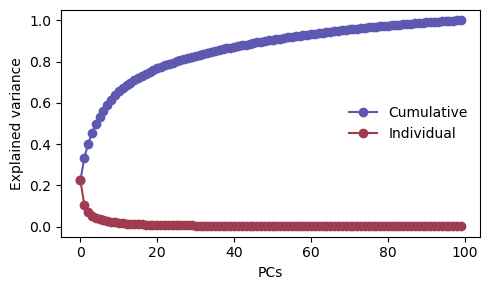

In [29]:
# Reorder data as subjects x time x parcels
X_seq = bold_zsc.transpose(0, 2, 1)

# Stack time across subjects only for PCA
X = X_seq.reshape(n_subjects * n_time, n_parcels)

# PCA across timepoints
projections, explained_variance_ratio, eigenvectors = compute_pca(X, n_components=n_parcels)
np.save(DATA_DIR / "pca_explained_variance_ratio.npy", explained_variance_ratio)

# Restore subject boundaries: subjects x time x PCs
n_pcs = projections.shape[1]
projections_seq = projections.reshape(n_subjects, n_time, n_pcs)

print("PCA projections sequence shape:", projections_seq.shape)

# Plot explained variance ratio
colors = plt.cm.twilight(np.linspace(0.3, 0.7, 2))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.cumsum(explained_variance_ratio), "o-", color=colors[0], label="Cumulative")
ax.plot(explained_variance_ratio, "o-", color=colors[1], label="Individual")
ax.set_xlabel("PCs")
ax.set_ylabel("Explained variance")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Model Selection - CV

In [20]:
def training_cv(n_components, n_states, X_seq, groups,
                n_splits=5, n_iter=200, n_restarts=10, zero_mean=True, random_state=0):
    '''
    Run stratified subject-wise cross-validation for a Gaussian HMM.
    '''
    n_subjects, n_time, n_parcels = X_seq.shape
    groups = np.asarray(groups)

    if len(groups) != n_subjects:
        raise ValueError("groups and X_seq have incompatible dimensions")

    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    results = []

    for fold, (train_idx, val_idx) in enumerate(splitter.split(np.arange(n_subjects), groups)):
        X_train, X_val = X_seq[train_idx], X_seq[val_idx]

        # Fit PCA on training subjects only
        pca = PCA(n_components=n_parcels, svd_solver="full")
        proj_train = pca.fit_transform(X_train.reshape(len(train_idx) * n_time, n_parcels))
        proj_val = pca.transform(X_val.reshape(len(val_idx) * n_time, n_parcels))

        proj_train_seq = proj_train.reshape(len(train_idx), n_time, n_parcels)
        proj_val_seq = proj_val.reshape(len(val_idx), n_time, n_parcels)

        emissions_train = jnp.asarray(proj_train_seq[:, :, :n_components])
        emissions_val = jnp.asarray(proj_val_seq[:, :, :n_components])

        best_hmm, best_params, _, best_lls, best_seed, ll_train, _ = fit_hmm_restarts(
            emissions=emissions_train, n_states=n_states, n_iter=n_iter, n_restarts=n_restarts,
            random_state=10000 + 1000 * fold + 100 * n_components + n_states, zero_mean=zero_mean
        )

        ll_val = hmm_data_ll(best_hmm, best_params, emissions_val)
        n_train_frames = len(train_idx) * n_time
        n_val_frames = len(val_idx) * n_time

        results.append({
            "fold": fold, "n_components": n_components, "n_states": n_states,
            "n_train_subjects": len(train_idx), "n_val_subjects": len(val_idx),
            "ll_train": ll_train, "ll_val": ll_val,
            "ll_train_per_subject": ll_train / len(train_idx),
            "ll_val_per_subject": ll_val / len(val_idx),
            "ll_train_per_frame": ll_train / n_train_frames,
            "ll_val_per_frame": ll_val / n_val_frames,
            "seed": int(best_seed), "fit_em_last": float(best_lls[-1]),
        })

    return results

In [ ]:
# Cross-validation settings
n_iter = 200
n_restarts = 10
n_splits = 5

n_components_list_cv = [25, 30, 35, 40, 45, 50]
n_states_list_cv = [2, 3, 4, 5, 6, 7, 8]

# Run CV
for zero_mean, name in [(True, "zeromean"), (False, "freemean")]:
    results = Parallel(n_jobs=-1, verbose=10)(
        delayed(training_cv)(n_components=n_components, n_states=n_states, X_seq=X_seq, groups=groups,
            n_splits=n_splits, n_iter=n_iter, n_restarts=n_restarts, zero_mean=zero_mean)
        for n_states in n_states_list_cv
        for n_components in n_components_list_cv
    )
    df_cv = pd.DataFrame([r for result in results for r in result])
    df_cv.to_csv(MAIN_DATA_DIR / f"hmm_crossval_{name}.csv", index=False)

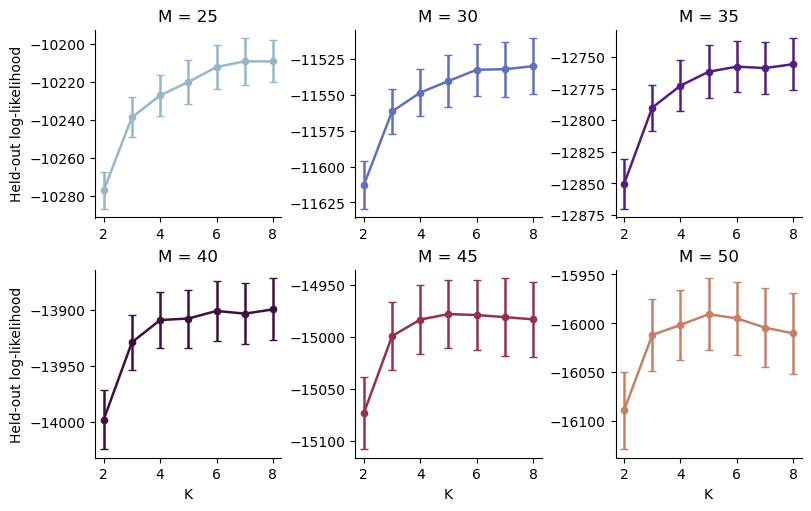

In [21]:
df_cv_zeromean = pd.read_csv(MAIN_DATA_DIR / "hmm_crossval_zeromean.csv")

plot_cv_model_selection(df_cv_zeromean, n_splits=5)
plt.show()

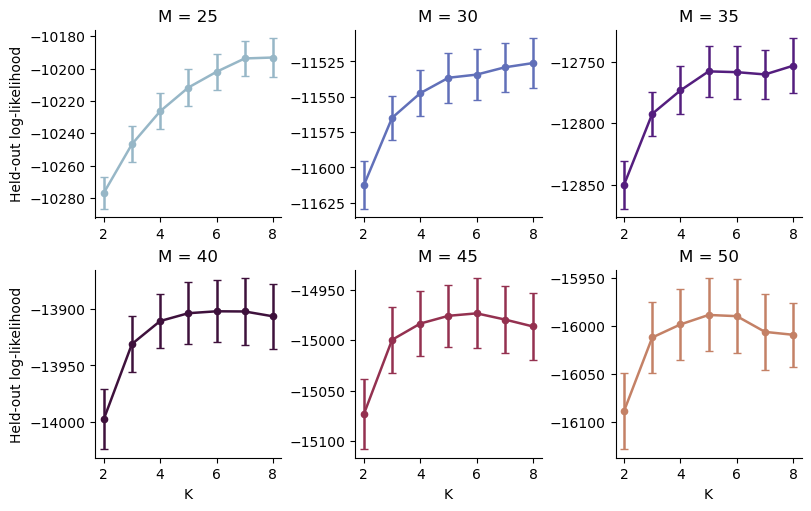

In [22]:
df_cv_freemean = pd.read_csv(MAIN_DATA_DIR / "hmm_crossval_freemean.csv")
plot_cv_model_selection(df_cv_freemean, n_splits=5)
plt.show()

## HMM Fit

In [23]:
def compute_posteriors_subjectwise(best_hmm, best_params, emissions, T=None, return_flat=True):
    '''
    Compute smoothed probabilities and Viterbi paths independently for each subject.
    '''
    emissions = jnp.asarray(emissions)

    if emissions.ndim != 3:
        raise ValueError("emissions must have shape: subjects x time x features")

    n_subjects, n_time, _ = emissions.shape

    if T is not None and n_time != T:
        raise ValueError(f"emissions has T={n_time}, but requested T={T}")

    gamma_list = []
    path_list = []

    for s in range(n_subjects):
        em_s = emissions[s]

        post_s = best_hmm.smoother(best_params, em_s)
        gamma_s = np.asarray(post_s.smoothed_probs)
        path_s = np.asarray(best_hmm.most_likely_states(best_params, em_s))

        gamma_list.append(gamma_s)
        path_list.append(path_s)

    gamma_seq = np.stack(gamma_list, axis=0)  # subjects x time x K
    path_seq = np.stack(path_list, axis=0)    # subjects x time

    if return_flat:
        gamma_all = gamma_seq.reshape(n_subjects * n_time, gamma_seq.shape[-1])
        path_all = path_seq.reshape(n_subjects * n_time)
        return gamma_all, path_all

    return gamma_seq, path_seq


def backproject_hmm_parameters(best_params, eigenvectors, n_components):
    '''
    Back-project HMM means and covariances from PCA space to parcel space.
    '''
    U = np.asarray(eigenvectors[:n_components, :])

    means_pca = np.asarray(best_params.emissions.means)
    covs_pca = np.asarray(best_params.emissions.covs)

    means_orig = means_pca @ U

    covs_orig = []

    for k in range(covs_pca.shape[0]):
        cov_orig = U.T @ covs_pca[k] @ U
        cov_orig = 0.5 * (cov_orig + cov_orig.T)
        covs_orig.append(cov_orig)

    covs_orig = np.stack(covs_orig)

    vars_orig = np.diagonal(covs_orig, axis1=1, axis2=2)

    if vars_orig.min() < -1e-8:
        raise ValueError(
            f"Negative reconstructed variance: {vars_orig.min()}"
        )

    stds_orig = np.sqrt(np.clip(vars_orig, 0, None))
    denom = stds_orig[:, :, None] * stds_orig[:, None, :]

    fcs_orig = np.divide(covs_orig, denom, out=np.zeros_like(covs_orig), where=denom > 0)
    fcs_orig = np.clip(fcs_orig, -1, 1)

    diagonal = np.arange(fcs_orig.shape[1])
    fcs_orig[:, diagonal, diagonal] = 1.0

    return {
        "means_orig": means_orig,
        "covs_orig": covs_orig,
        "fcs_orig": fcs_orig,
    }

In [ ]:
# Select HMM configuration and parameters
m_components = 30
k_states = 3
zero_mean = True

n_iter = 200
n_restarts = 20
random_state = 23

# Batched emissions: subjects x time x PCs
emissions = jnp.asarray(projections_seq[:, :, :m_components])
n_obs = n_subjects * n_time

# Fit HMM
best_hmm, best_params, best_props, best_lls, best_seed, best_ll_data, restart_rows = fit_hmm_restarts(
    emissions=emissions,
    n_states=k_states,
    n_iter=n_iter,
    n_restarts=n_restarts,
    random_state=random_state + 1000*m_components + k_states,
    zero_mean=zero_mean,
)

df_final_fit = pd.DataFrame(restart_rows)

# Save HMM fit
save_hmm_fit(MAIN_DATA_DIR, df_final_fit, best_params, best_lls)

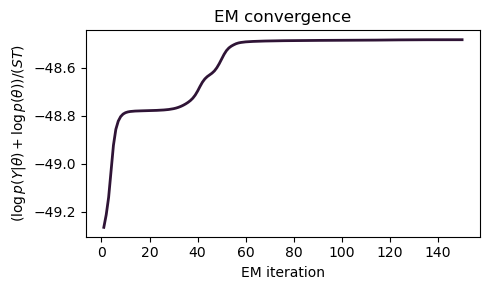

In [64]:
# Load HMM fit
m_components = 30
k_states = 3
zero_mean = True
n_obs = n_subjects * n_time
emissions = jnp.asarray(projections_seq[:, :, :m_components])

best_hmm, best_params, best_props, best_lls, best_seed, best_ll_data, df_final_fit = load_hmm_fit(
    MAIN_DATA_DIR,
    n_states=k_states,
    emission_dim=m_components,
    zero_mean=zero_mean,
)

# EM convergence plot for selected HMM
em_trace = np.asarray(best_lls, dtype=float)
em_trace_per_obs = em_trace / n_obs

max_iter_plot = 150
stop = min(max_iter_plot + 1, len(em_trace_per_obs))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.arange(1, stop), em_trace_per_obs[1:stop], linewidth=2, color=plt.cm.twilight(0.5))

ax.set_xlabel("EM iteration")
ax.set_ylabel(r"$(\log p(Y|\theta) + \log p(\theta)) / (S T)$")
ax.set_title("EM convergence")
plt.tight_layout()
plt.show()

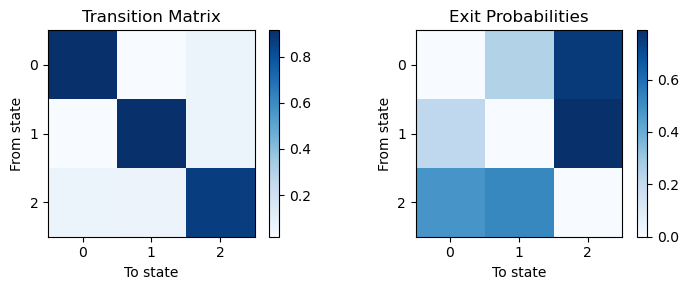

In [65]:
# Estimated transition matrix
A_est = np.asarray(best_params.transitions.transition_matrix)

# Exit probabilities: remove self-transitions and renormalize rows
A_exit_est = A_est.copy()
np.fill_diagonal(A_exit_est, 0.0)

row_sum = A_exit_est.sum(axis=1, keepdims=True)
A_exit_est = np.divide(A_exit_est, row_sum, out=np.zeros_like(A_exit_est), where=row_sum != 0)

# Plot transition matrices
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3))

im0 = axs[0].imshow(A_est, cmap="Blues")
axs[0].set_title("Transition Matrix")
axs[0].set_xticks(np.arange(k_states))
axs[0].set_yticks(np.arange(k_states))
axs[0].set_xlabel("To state")
axs[0].set_ylabel("From state")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(A_exit_est, cmap="Blues")
axs[1].set_title("Exit Probabilities")
axs[1].set_xticks(np.arange(k_states))
axs[1].set_yticks(np.arange(k_states))
axs[1].set_xlabel("To state")
axs[1].set_ylabel("From state")
plt.colorbar(im1, ax=axs[1], fraction=0.046)

plt.tight_layout()
plt.show()

In [66]:
# Extract posterior state probabilities and Viterbi path
gamma_seq, path_seq = compute_posteriors_subjectwise(best_hmm, best_params, emissions, T=n_time, return_flat=False)

print("gamma_seq shape:", gamma_seq.shape)  # subjects x time x K
print("path_seq shape:", path_seq.shape)    # subjects x time

# Save posterior results
np.save(MAIN_DATA_DIR / "gamma_seq.npy", gamma_seq)
np.save(MAIN_DATA_DIR / "path_seq.npy", path_seq)

gamma_seq shape: (217, 240, 3)
path_seq shape: (217, 240)


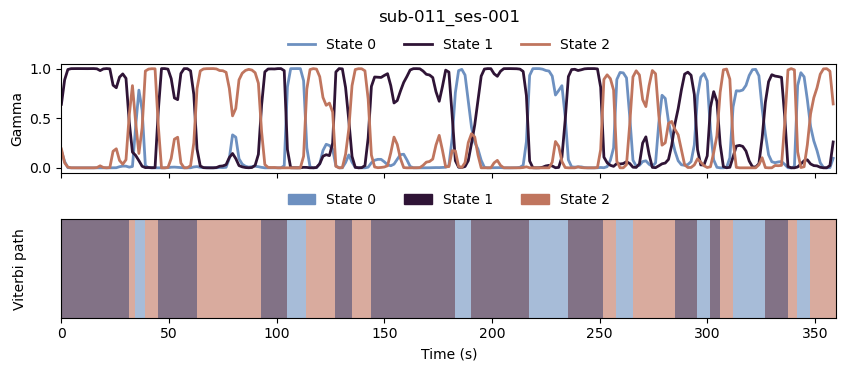

In [69]:
# Plot gamma probabilities and Viterbi path for one subject
sub_idx = np.random.randint(0, n_subjects)
time = np.arange(n_time) * TR

gamma_sub = gamma_seq[sub_idx]
path_sub = path_seq[sub_idx].astype(int)

colors = plt.cm.twilight(np.linspace(0.2, 0.8, k_states))
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(k_states + 1) - 0.5, cmap.N)

fig, axes = plt.subplots(2, 1, figsize=(10, 3.3), sharex=True, gridspec_kw={"height_ratios": [1.0, 0.9], "hspace": 0.45})

# Gamma probabilities
axes[0].set_prop_cycle(cycler(color=colors))

for k in range(k_states):
    axes[0].plot(time, gamma_sub[:, k], label=f"State {k}", linewidth=2)

axes[0].set_ylabel("Gamma")
axes[0].set_title(subjects[sub_idx], pad=30)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.35), ncol=k_states, frameon=False)

# Viterbi path
axes[1].imshow(path_sub[np.newaxis, :], aspect="auto", interpolation="nearest", cmap=cmap, norm=norm,
               extent=[time[0], time[-1] + TR, 0, 1], alpha=0.6)

handles = [mpatches.Patch(color=colors[k], label=f"State {k}") for k in range(k_states)]
axes[1].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.40), ncol=k_states, frameon=False)

axes[1].set_yticks([])
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Viterbi path", labelpad=25)

plt.show()

In [70]:
# Back-project HMM parameters from PCA space to parcel space
state_params = backproject_hmm_parameters(best_params, eigenvectors, m_components)

means_orig = state_params["means_orig"]
covs_orig = state_params["covs_orig"]
fcs_orig = state_params["fcs_orig"]

# Save back-projected HMM parameters
np.save(MAIN_DATA_DIR / "means_orig.npy", means_orig)
np.save(MAIN_DATA_DIR / "covs_orig.npy", covs_orig)
np.save(MAIN_DATA_DIR / "fcs_orig.npy", fcs_orig)

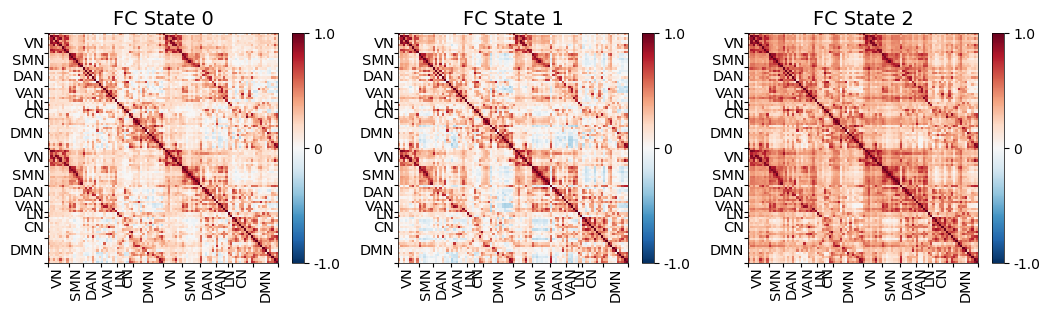

In [71]:
# Plot State means
if not zero_mean:
    plot_state_means(means_orig, network_labels, network_names, sort=True, figsize=(10, 3))
    plt.title("Mean BOLD activity")
    plt.tight_layout()
    plt.show()

# Plot State FC matrices
plot_matrices([fcs_orig[k] for k in range(k_states)], network_labels=network_labels, network_names=network_names,
              titles=[f"FC State {i}" for i in range(k_states)],
              vminvmax=[[-1, 1] for k in range(k_states)], center=0,
              cmap="RdBu_r", figsize_per_matrix=(3.5, 3), sort=False)
plt.show()

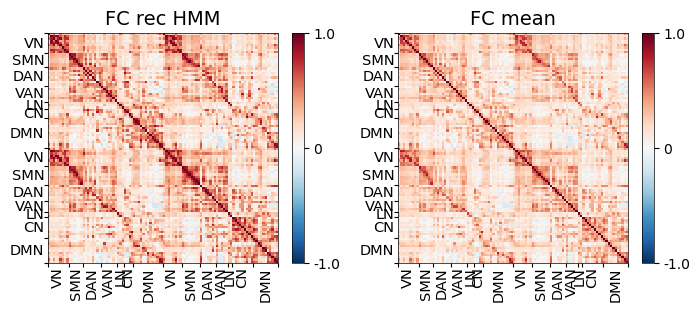

Correlation empirical FC vs HMM reconstructed FC: r = 0.996


In [42]:
# Reconstruct the global FC from the HMM marginal mixture using empirical state occupancies
fc_empirical = np.asarray(fcs_all).mean(axis=0)

# Mean state occupancy across all subjects and time points
alpha_k = np.asarray(gamma_seq).mean(axis=(0, 1))

if zero_mean:
    mu_mix = np.zeros(means_orig.shape[1])
    cov_mix = sum(alpha_k[k] * covs_orig[k] for k in range(k_states))
else:
    mu_mix = np.sum(alpha_k[:, None] * means_orig, axis=0)
    cov_mix = sum(alpha_k[k] * (covs_orig[k] + np.outer(means_orig[k], means_orig[k])) for k in range(k_states)) - np.outer(mu_mix, mu_mix)

# Convert covariance to correlation
stds = np.sqrt(np.diag(cov_mix))
fc_reconstructed = cov_mix / np.outer(stds, stds)

plot_matrices([fc_reconstructed, fc_empirical], network_labels=network_labels, network_names=network_names,
              titles=["FC rec HMM", "FC mean"], vminvmax=[[-1, 1], [-1, 1]],
              cmap="RdBu_r", figsize_per_matrix=(3.5, 3), sort=False)
plt.show()

idx = np.triu_indices_from(fc_empirical, k=1)
r_fc = np.corrcoef(fc_empirical[idx], fc_reconstructed[idx])[0, 1]
print(f"Correlation empirical FC vs HMM reconstructed FC: r = {r_fc:.3f}")

np.save(MAIN_DATA_DIR / "hmm_reconstructed_fc.npy", fc_reconstructed)

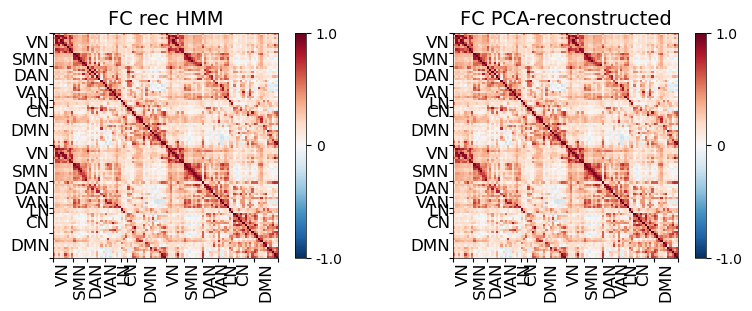

Correlation PCA-reconstructed FC vs HMM reconstructed FC: r = 1.000


In [43]:
# Compare with the empirical FC reconstructed from retained PCs
X_pca_rec = projections[:, :m_components] @ eigenvectors[:m_components, :]
fc_empirical_pca = np.corrcoef(X_pca_rec, rowvar=False)

idx = np.triu_indices_from(fc_empirical_pca, k=1)
r_pca = np.corrcoef(fc_empirical_pca[idx], fc_reconstructed[idx])[0, 1]

plot_matrices([fc_reconstructed, fc_empirical_pca], network_labels=network_labels, network_names=network_names,
              titles=["FC rec HMM", "FC PCA-reconstructed"], vminvmax=[[-1, 1], [-1, 1]],
              cmap="RdBu_r", figsize_per_matrix=(4, 3), sort=False)
plt.show()

print(f"Correlation PCA-reconstructed FC vs HMM reconstructed FC: r = {r_pca:.3f}")

### HMM-metrics

In [72]:
def build_hmm_metrics(gamma_all, path_all, subjects, df_sel, T, TR):
    '''
    Build subject/state-level HMM metrics (Fractional Occupancy, Dwell TIme, Switch Rate).
    '''
    gamma_all = np.asarray(gamma_all, dtype=float)
    path_all = np.asarray(path_all, dtype=int)

    n_subjects = len(subjects)

    if gamma_all.ndim == 2:
        K = gamma_all.shape[1]
        gamma_seq = gamma_all.reshape(n_subjects, T, K)
    elif gamma_all.ndim == 3:
        gamma_seq = gamma_all
        K = gamma_seq.shape[2]
    else:
        raise ValueError("gamma_all must be 2D or 3D")

    if path_all.ndim == 1:
        path_seq = path_all.reshape(n_subjects, T)
    elif path_all.ndim == 2:
        path_seq = path_all
    else:
        raise ValueError("path_all must be 1D or 2D")

    records = []

    for s, pid in enumerate(subjects):

        gamma = gamma_seq[s]
        path = path_seq[s]

        switch_rate = np.mean(path[1:] != path[:-1])
        group = df_sel.loc[pid, "group"]

        for k in range(K):
            fo_soft = gamma[:, k].mean()
            fo_hard = np.mean(path == k)

            runs = [len(list(g)) for st, g in groupby(path) if st == k]
            dwell = np.mean(runs) * TR if runs else 0.0

            records.append({
                "participant_id": pid,
                "Group": group,
                "State": f"State{k}",
                "FO_soft": fo_soft,
                "FO_hard": fo_hard,
                "Dwell": dwell,
                "SwitchRate": switch_rate,
            })

    return pd.DataFrame.from_records(records)

In [73]:
# Load posterior state probabilities and Viterbi paths
gamma_seq = np.load(MAIN_DATA_DIR / "gamma_seq.npy")
path_seq = np.load(MAIN_DATA_DIR / "path_seq.npy")

# Compute subject-level HMM metrics
df_hmm = build_hmm_metrics(gamma_seq, path_seq, subjects, df_sel, T_PER_SUBJ, TR)

# Save metrics
df_hmm.to_csv(MAIN_DATA_DIR / "hmm_metrics.csv", index=False)

### Group comparison (HC-MS)

In [74]:
def compare_hmm_metrics_groups(df_hmm, metrics=("FO_soft", "Dwell", "SwitchRate"), alpha=0.05):
    '''
    Compare HMM metrics between MS and HC using two-sided Mann-Whitney U tests with global FDR correction.
    '''
    states = sorted(df_hmm["State"].unique(), key=lambda x: int(str(x).replace("State", "")))
    rows = []

    df_sr = df_hmm.groupby("participant_id", as_index=False).agg(
        Group=("Group", "first"), SwitchRate=("SwitchRate", "first")
    )

    for metric in metrics:
        if metric == "SwitchRate":
            ms = df_sr.query("Group == 'MS'")[metric].dropna()
            hc = df_sr.query("Group == 'HC'")[metric].dropna()
            p = mannwhitneyu(ms, hc, alternative="two-sided").pvalue
            rows.append({"Metric": metric, "State": None, "p_unc": p})

        else:
            for state in states:
                ms = df_hmm.query("Group == 'MS' and State == @state")[metric].dropna()
                hc = df_hmm.query("Group == 'HC' and State == @state")[metric].dropna()
                p = mannwhitneyu(ms, hc, alternative="two-sided").pvalue
                rows.append({"Metric": metric, "State": state, "p_unc": p})

    df_results = pd.DataFrame(rows)
    reject, p_fdr, _, _ = multipletests(df_results["p_unc"], alpha=alpha, method="fdr_bh")
    df_results["p_fdr"] = p_fdr
    df_results["significant"] = reject

    return df_results, df_sr


def plot_hmm_metrics_groups(df_hmm, df_group_comparison):
    '''
    Plot HMM metrics by group with FDR-corrected significance annotations.
    '''
    states = sorted(df_hmm["State"].unique(), key=lambda x: int(str(x).replace("State", "")))
    group_order = ["MS", "HC"]

    metrics = ["FO_soft", "Dwell", "SwitchRate"]
    titles = ["Fractional Occupancy", "Dwell Time", "Switching Rate"]

    df_sr = df_hmm.groupby("participant_id", as_index=False).agg(
        Group=("Group", "first"), SwitchRate=("SwitchRate", "first")
    )

    fig = plt.figure(figsize=(8, 2), constrained_layout=True)
    gs = gridspec.GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 0.3])

    for i, (metric, title) in enumerate(zip(metrics, titles)):
        ax = fig.add_subplot(gs[0, i])

        if metric != "SwitchRate":
            sns.boxplot(data=df_hmm, x="State", y=metric, hue="Group", order=states, hue_order=group_order,
                        showfliers=False, palette="Set2", ax=ax)

            pairs, pvals = [], []

            for state in states:
                info = df_group_comparison[
                    (df_group_comparison["Metric"] == metric) &
                    (df_group_comparison["State"] == state)
                ]

                if not info.empty and bool(info["significant"].iloc[0]):
                    pairs.append(((state, "MS"), (state, "HC")))
                    pvals.append(float(info["p_fdr"].iloc[0]))

            if pairs:
                annot = Annotator(ax, pairs=pairs, data=df_hmm, x="State", y=metric, hue="Group",
                                  order=states, hue_order=group_order)
                annot.configure(test=None, text_format="star", loc="inside", verbose=False)
                annot.set_pvalues(pvals)
                annot.annotate()

            ax.get_legend().remove()
            ax.set_ylabel(metric.replace("_", " "))

        else:
            sns.boxplot(data=df_sr, x="Group", y="SwitchRate", hue="Group", order=group_order,
                        hue_order=group_order, palette="Set2", legend=False, showfliers=False, ax=ax)

            info = df_group_comparison[df_group_comparison["Metric"] == "SwitchRate"]

            if not info.empty and bool(info["significant"].iloc[0]):
                annot = Annotator(ax, pairs=[("MS", "HC")], data=df_sr, x="Group",
                                  y="SwitchRate", order=group_order)
                annot.configure(test=None, text_format="star", loc="inside", verbose=False)
                annot.set_pvalues([float(info["p_fdr"].iloc[0])])
                annot.annotate()

            ax.set_ylabel("SwitchRate")

        ax.set_xlabel("")
        ax.set_title(title, fontsize=11)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    handles, labels = fig.axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.55, 1.15), ncol=2, frameon=False)

    return fig

,Metric,State,p_unc,p_fdr,significant
0,FO_soft,State0,0.014434,0.045165,True
1,FO_soft,State1,0.005626,0.039381,True
2,FO_soft,State2,0.328359,0.383086,False
3,Dwell,State0,0.030180,0.052815,False
4,Dwell,State1,0.019356,0.045165,True
5,Dwell,State2,0.470673,0.470673,False
6,SwitchRate,None,0.310237,0.383086,False


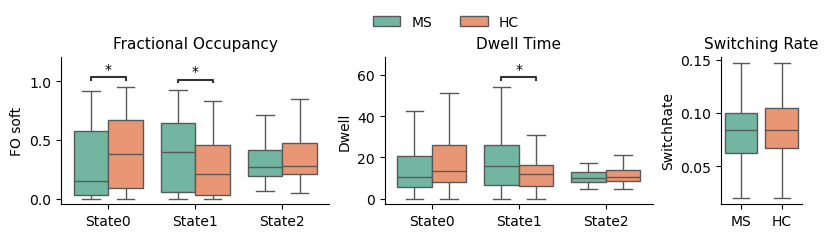

In [75]:
# MS vs HC comparison of HMM metrics
df_group_comparison, df_sr = compare_hmm_metrics_groups(df_hmm, metrics=("FO_soft", "Dwell", "SwitchRate"))
display(df_group_comparison)

df_group_comparison.to_csv(MAIN_DATA_DIR / "hmm_group_comparison.csv", index=False)

plot_hmm_metrics_groups(df_hmm, df_group_comparison)
plt.show()

### Clinical correlations (MS)

In [76]:
def compute_hmm_clinical_correlations(df_hmm, df_sel, clinical_vars=("EDSS", "SDMT", "BPF", "lesion_load"),
                                      metrics=("FO_soft", "Dwell", "SwitchRate"), alpha=0.05):
    '''
    Compute Spearman correlations between HMM metrics and clinical variables in MS subjects with global FDR correction.
    '''
    df_ms_hmm = df_hmm.query("Group == 'MS'").copy()
    df_ms_clin = df_sel.query("group == 'MS'").copy()

    if "participant_id" not in df_ms_clin.columns:
        df_ms_clin = df_ms_clin.reset_index()

    df_merged = df_ms_hmm.merge(df_ms_clin, on="participant_id", suffixes=("", "_clin"), validate="many_to_one")
    states = sorted(df_merged["State"].unique(), key=lambda x: int(str(x).replace("State", "")))

    cols = list(clinical_vars) + list(metrics)
    for col in cols:
        df_merged[col] = pd.to_numeric(df_merged[col], errors="coerce")

    if df_merged[cols].isna().any().any():
        raise ValueError("Missing values found in data used for correlations")

    df_subject = df_merged.groupby("participant_id", as_index=False).agg(
        **{var: (var, "first") for var in list(metrics) + list(clinical_vars)}
    )

    rows = []

    for metric in metrics:
        if metric == "SwitchRate":
            for clin_var in clinical_vars:
                rho, p = spearmanr(df_subject[metric], df_subject[clin_var])
                rows.append({"State": None, "HMM_metric": metric, "Clinical_var": clin_var,
                             "Spearman_rho": rho, "p_value": p, "n": len(df_subject)})

        else:
            for state in states:
                df_state = df_merged[df_merged["State"] == state]

                for clin_var in clinical_vars:
                    rho, p = spearmanr(df_state[metric], df_state[clin_var])
                    rows.append({"State": state, "HMM_metric": metric, "Clinical_var": clin_var,
                                 "Spearman_rho": rho, "p_value": p, "n": len(df_state)})

    df_corr = pd.DataFrame(rows)
    reject, p_fdr, _, _ = multipletests(df_corr["p_value"], alpha=alpha, method="fdr_bh")
    df_corr["p_fdr"] = p_fdr
    df_corr["significant"] = reject

    return df_corr, df_merged


def plot_hmm_clinical_correlations(df_merged, df_corr, metrics_to_plot=("FO_soft", "Dwell"),
                                   clinical_vars_to_plot=("BPF", "lesion_load"),
                                   states_to_plot=("State0", "State1")):
    '''
    Plot selected HMM-clinical correlations in MS subjects.
    '''
    scatter_color = "#2166ac"
    line_color = "#b2182b"

    nrows = len(clinical_vars_to_plot)
    ncols = len(metrics_to_plot) * len(states_to_plot)

    fig = plt.figure(figsize=(7, nrows * 2), constrained_layout=True)
    gs = gridspec.GridSpec(nrows, ncols, figure=fig, wspace=0.15)
    label_map = {"BPF": "BPF", "lesion_load": "Lesion Load"}
    
    for r, clin_var in enumerate(clinical_vars_to_plot):
        for m, metric in enumerate(metrics_to_plot):
            for s, state in enumerate(states_to_plot):
                c = m * len(states_to_plot) + s
                ax = fig.add_subplot(gs[r, c])

                df_state = df_merged[df_merged["State"] == state]
                info = df_corr.query("State == @state and HMM_metric == @metric and Clinical_var == @clin_var")

                if info.empty:
                    ax.axis("off")
                    continue

                rho = float(info["Spearman_rho"].iloc[0])
                p_fdr = float(info["p_fdr"].iloc[0])

                sns.regplot(x=df_state[metric], y=df_state[clin_var], ax=ax,
                            scatter_kws={"s": 30, "alpha": 0.55, "color": scatter_color},
                            line_kws={"color": line_color})

                metric_label = "DT" if metric == "Dwell" else "FO" if metric == "FO_soft" else metric
                ax.set_xlabel(f"{metric_label} - {state}")

                if metric == "Dwell":
                    ax.set_xticks([0, 50])
                    ax.set_xlim(-3, 60)
                elif metric == "FO_soft":
                    ax.set_xticks([0, 0.5])
                    ax.set_xlim(-0.05, 1.05)

                if clin_var == "lesion_load":
                    ax.set_ylim(top=30000)

                if c == 0:
                    ax.set_ylabel(label_map.get(clin_var, clin_var))
                else:
                    ax.set_ylabel("")
                    ax.tick_params(axis="y", labelleft=False, length=3)

                p_line = r"$p < 0.001$" if p_fdr < 0.001 else rf"$p = {p_fdr:.3f}$"
                text = r"$\rho = %.2f$" % rho + "\n" + p_line

                ax.text(0.1, 0.95, text, transform=ax.transAxes, fontsize=10, va="top",
                        bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3"))

                ax.spines["top"].set_visible(False)
                ax.spines["right"].set_visible(False)

    return fig

,State,HMM_metric,Clinical_var,Spearman_rho,p_value,n,p_fdr,significant
2,State0,FO_soft,BPF,0.366772,0.000033,122,0.000455,True
3,State0,FO_soft,lesion_load,-0.253853,0.004781,122,0.032912,True
6,State1,FO_soft,BPF,-0.248030,0.005877,122,0.032912,True
11,State2,FO_soft,lesion_load,0.233953,0.009498,122,0.044324,True
14,State0,Dwell,BPF,0.393829,0.000007,122,0.000201,True
15,State0,Dwell,lesion_load,-0.277578,0.001965,122,0.018341,True


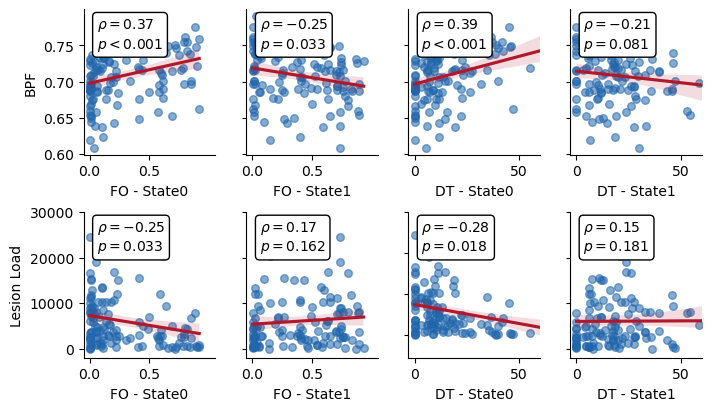

In [77]:
df_hmm_corr, df_ms_hmm_clin = compute_hmm_clinical_correlations(df_hmm, df_sel)
display(df_hmm_corr[df_hmm_corr["significant"]])

df_hmm_corr.to_csv(MAIN_DATA_DIR / "hmm_clinical_correlations.csv", index=False)

plot_hmm_clinical_correlations(df_ms_hmm_clin, df_hmm_corr, clinical_vars_to_plot=("BPF", "lesion_load"), states_to_plot=("State0", "State1"))
plt.show()

### QC states

In [78]:
def zscore_subjectwise(x):
    '''
    Z-score subject x time data within each subject.
    '''
    x = np.asarray(x, dtype=float)
    x_z = np.zeros_like(x, dtype=float)

    for s in range(x.shape[0]):
        mu = np.nanmean(x[s])
        sigma = np.nanstd(x[s])
        x_z[s] = np.nan if sigma == 0 or np.isnan(sigma) else (x[s] - mu) / sigma

    return x_z


def compute_state_measure_associations(gamma_seq, measures):
    '''
    Compute gamma-weighted mean z-scores of subject-wise time-varying measures for each HMM state.
    '''
    gamma_seq = np.asarray(gamma_seq)
    n_subjects, n_time, K = gamma_seq.shape

    state_measure = pd.DataFrame(index=[f"State{k}" for k in range(K)], columns=measures.keys(), dtype=float)

    for measure_name, q in measures.items():
        q = np.asarray(q, dtype=float)

        if q.shape != (n_subjects, n_time):
            raise ValueError(f"{measure_name} has shape {q.shape}, expected {(n_subjects, n_time)}")

        q_z = zscore_subjectwise(q)

        for k in range(K):
            w = gamma_seq[:, :, k]
            valid = np.isfinite(q_z) & np.isfinite(w)
            den = np.sum(w[valid])
            state_measure.loc[f"State{k}", measure_name] = np.sum(w[valid] * q_z[valid]) / den if den > 0 else np.nan

    return state_measure


def compute_bad_frame_probability(gamma_seq, bad_defs):
    '''
    Compute gamma-weighted bad-frame probability for each HMM state.
    '''
    records = []
    _, _, K = gamma_seq.shape

    for bad_name, bad_info in bad_defs.items():
        bad = np.asarray(bad_info["bad"], dtype=bool)
        valid = np.asarray(bad_info["valid"], dtype=bool)
        baseline_p_bad = np.mean(bad[valid])

        for k in range(K):
            w = gamma_seq[:, :, k]
            valid_soft = valid & np.isfinite(w)
            den = np.sum(w[valid_soft])
            p_bad_state = np.sum(w[valid_soft] * bad[valid_soft]) / den if den > 0 else np.nan

            delta_p_bad = p_bad_state - baseline_p_bad
            ratio_to_baseline = p_bad_state / baseline_p_bad if baseline_p_bad > 0 else np.nan

            records.append({
                "State": f"State{k}",
                "BadFrame": bad_name,
                "baseline_p_bad": baseline_p_bad,
                "soft_p_bad_given_state": p_bad_state,
                "delta_p_bad": delta_p_bad,
                "delta_percentage_points": 100 * delta_p_bad,
                "ratio_to_baseline": ratio_to_baseline,
            })

    return pd.DataFrame.from_records(records)


def compute_state_qc(gamma_seq, bold_zsc, fd, dvars, fd_thresh=0.5, dvars_percentile=95):
    '''
    Compute HMM state associations with signal/QC measures and bad-frame probabilities.
    '''
    measures = {
        "GS_abs": np.abs(bold_zsc.mean(axis=1)),
        "DVARS": dvars,
        "parcel STD": bold_zsc.std(axis=1),
        "FD": fd,
    }

    state_measure = compute_state_measure_associations(gamma_seq, measures)

    dvars_thr = np.nanpercentile(dvars, dvars_percentile, axis=1)
    bad_defs = {
        f"DVARS top {100 - dvars_percentile:g}%": {"bad": dvars > dvars_thr[:, None], "valid": np.isfinite(dvars)},
        f"FD > {fd_thresh}": {"bad": fd > fd_thresh, "valid": np.isfinite(fd)},
    }

    bad_prob_df = compute_bad_frame_probability(gamma_seq, bad_defs)

    return state_measure, bad_prob_df


def plot_state_measure_heatmap(state_measure):
    '''
    Plot gamma-weighted state associations with signal and QC measures.
    '''
    state_measure = state_measure.astype(float)
    vmax = np.nanmax(np.abs(state_measure.values))

    fig, ax = plt.subplots(figsize=(6, 3))
    im = ax.imshow(state_measure.values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)

    ax.set_xticks(np.arange(state_measure.shape[1]))
    ax.set_xticklabels(state_measure.columns, rotation=45, ha="right")
    ax.set_yticks(np.arange(state_measure.shape[0]))
    ax.set_yticklabels(state_measure.index)

    for i in range(state_measure.shape[0]):
        for j in range(state_measure.shape[1]):
            val = state_measure.iloc[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="black")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Gamma-weighted mean (z-score)")

    ax.set_title("State association with signal/QC measures")
    fig.tight_layout()

    return fig, ax


def plot_bad_frame_probabilities(bad_prob_df, bad_order=("DVARS top 5%", "FD > 0.5"), colors=None):
    '''
    Plot posterior bad-frame probabilities by HMM state together with the unconditional bad-frame probability.
    '''
    states = sorted(bad_prob_df["State"].unique(), key=lambda x: int(str(x).replace("State", "")))
    K = len(states)

    if colors is None:
        colors = plt.cm.twilight(np.linspace(0.1, 0.9, K))

    fig, axes = plt.subplots(1, len(bad_order), figsize=(3.5 * len(bad_order), 3), sharey=False)

    if len(bad_order) == 1:
        axes = [axes]

    for j, bad_name in enumerate(bad_order):
        ax = axes[j]

        d = bad_prob_df[bad_prob_df["BadFrame"] == bad_name].set_index("State").loc[states].reset_index()

        x = np.arange(K)
        y = 100 * d["soft_p_bad_given_state"].to_numpy()
        baseline = 100 * d["baseline_p_bad"].iloc[0]
        delta_pp = d["delta_percentage_points"].to_numpy()

        ax.bar(x, y, color=colors, alpha=0.8, edgecolor="black", linewidth=0.8)
        ax.axhline(baseline, color="darkred", linestyle="--", linewidth=1.2, label="P(bad frame)")

        for i in range(K):
            ax.text(x[i], y[i], f"{y[i]:.1f}%\n({delta_pp[i]:+.1f} pp)", ha="center", va="bottom", fontsize=9)

        ymax = max(np.nanmax(y), baseline) * 1.35
        ax.set_ylim(0, ymax)
        ax.set_xticks(x)
        ax.set_xticklabels(states)
        ax.set_title(bad_name)
        ax.set_ylabel("P(bad frame | state) (%)")
        ax.legend(frameon=False, loc="upper right")

    fig.tight_layout()

    return fig, axes

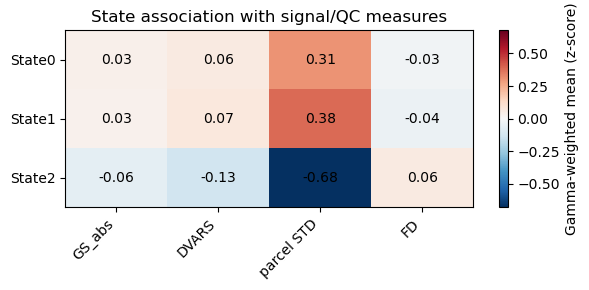

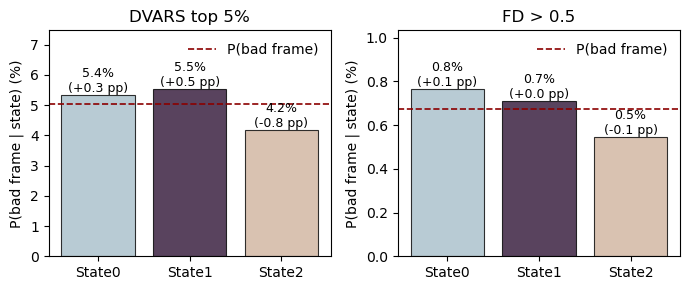

In [79]:
# State-QC analyses
state_measure, bad_prob_df = compute_state_qc(gamma_seq, bold_zsc, fd, dvars, fd_thresh=0.5, dvars_percentile=95)

# Plot satets QC
plot_state_measure_heatmap(state_measure)
plt.show()

plot_bad_frame_probabilities(bad_prob_df)
plt.show()

# Save QC dataframes
state_measure.reset_index(names="State").to_csv(MAIN_DATA_DIR / "state_signal_qc.csv", index=False)
bad_prob_df.to_csv(MAIN_DATA_DIR / "bad_frame_probabilities.csv", index=False)

# Optimal Transport

#### OT cost computation from HMM posterior transition probabilities

Subject's joint transistion distribution transition ($Q^s$) is estimated from the HMM posterior transition probabilities returned by the Dynamax smoother. For each subject, we run the smoother on that subject's time series providing posterior joint transition probabilities of the form:

$p(z_t=k,z_{t+1}=l \mid X^s)$

These probabilities are summed over time and normalized to obtain a subject's joint transition distribution:

$
Q^s_{kl}=\frac{1}{T-1}\sum_{t=1}^{T-1}p(z_t=k,z_{t+1}=l \mid X^s) \qquad \sum_{k,l}Q^s_{kl}=1
$

Thus posterior uncertainty is preserverd. The marginals of ($Q^s$) are:

$\pi^{s,-}_k=\sum_l Q^s_{kl}\qquad \pi^{s,+}_l=\sum_k Q^s_{kl}$

The first marginal describes how often the subject starts a transition from state (k), while the second describes how often the subject arrives in state (l). These quantities are very close to the soft fractional occupancies, but not exactly identical, because fractional occupancy is computed over (T) time points, whereas the transition distribution is computed over (T-1) transitions. There is a small discrepancy of the order 1/(T-1). The OT cost is defined as:

$C_{sr} = \min_{P \in \mathcal{U}_{sr}} D_{\mathrm{KL}}(P\,\Vert\,Q^{s}),$

where:

$\mathcal{U}_{sr} = \{P \geq 0 \mid \sum_l P_{kl} = \pi_k^{-,s},\; \sum_k P_{kl} = \pi_l^{+,r}\}$

Thus, in the cost from subject (s) to subject (r), the reference dynamics are given by ($Q^s$), the source marginal is the row marginal of ($Q^s$), and the target marginal is the column marginal of ($Q^r$).

In [56]:
def compute_transition_matrices_dynamax(best_hmm, best_params, emissions):
    '''
    Compute joint transition probability matrices from posterior transition probabilities.
    '''
    emissions = jnp.asarray(emissions)

    if emissions.ndim != 3:
        raise ValueError("emissions must have shape: subjects x time x features")

    N_subjects = emissions.shape[0]
    Q_all = []

    for s in range(N_subjects):
        em_s = emissions[s]

        post_s = best_hmm.smoother(best_params, em_s)
        trans = np.asarray(post_s.trans_probs)

        if trans.ndim != 2:
            raise ValueError(f"Expected post_s.trans_probs with shape (K, K),"
                             f"got shape {trans.shape} for subject {s}")

        if trans.sum() <= 0:
            raise ValueError(f"Transition matrix has non-positive sum for subject {s}")

        Q = trans / trans.sum()  # joint P(i,j) 
        Q_all.append(Q)

    return np.asarray(Q_all)


def f(G):
    G = np.maximum(G, 1e-15)
    return np.sum(G * np.log(G))


def df(G):
    G = np.maximum(G, 1e-15)
    return np.log(G) + 1.0


def kl(P, Q):
    '''
    Compute KL divergence.
    '''
    P = np.maximum(P, 1e-15)
    Q = np.maximum(Q, 1e-15)

    P = P / P.sum()
    Q = Q / Q.sum()

    return np.sum(P * (np.log(P) - np.log(Q)))


def compute_sb_costs(Q_all, eps=1.0):
    '''
    Compute directional Schrödinger bridge / KL transition costs.
    '''
    Q_all = np.asarray(Q_all, dtype=float)

    Q_use = np.maximum(Q_all, 1e-15)
    Q_use = Q_use / Q_use.sum(axis=(1, 2), keepdims=True)

    pi_source_all = Q_use.sum(axis=2)
    pi_target_all = Q_use.sum(axis=1)

    N = len(Q_use)
    cost_matrix = np.zeros((N, N), dtype=float)

    for i in tqdm(range(N), desc="SB costs"):
        Q_i = Q_use[i]
        M = -np.log(Q_i)
        a = pi_source_all[i]

        for j in range(N):
            b = pi_target_all[j]
            P = ot.optim.cg(a, b, M, eps, f, df, verbose=False)
            cost_matrix[i, j] = kl(P, Q_i) + (eps - 1.0) * f(P)

    return cost_matrix, pi_source_all, pi_target_all, Q_use


def compute_sb_costs_parallel(Q_all, eps=1.0, n_jobs=-1, backend="loky"):
    '''
    Parallel version of compute_sb_costs.
    '''
    Q_all = np.asarray(Q_all, dtype=float)

    Q_use = np.maximum(Q_all, 1e-15)
    Q_use = Q_use / Q_use.sum(axis=(1, 2), keepdims=True)

    pi_source_all = Q_use.sum(axis=2)  # row marginals: pre-transition occupancy
    pi_target_all = Q_use.sum(axis=1)  # column marginals: post-transition occupancy

    N = len(Q_use)

    def _compute_row(i):
        row = np.zeros(N, dtype=float)

        Q_i = Q_use[i]
        M = -np.log(Q_i)
        a = pi_source_all[i]

        for j in range(N):
            b = pi_target_all[j]
            P = ot.optim.cg(a, b, M, eps, f, df, verbose=False)
            row[j] = kl(P, Q_i) + (eps - 1.0) * f(P)

        return row

    rows = Parallel(n_jobs=n_jobs, backend=backend)(
        delayed(_compute_row)(i) for i in tqdm(range(N), desc="SB costs")
    )

    return np.vstack(rows), pi_source_all, pi_target_all, Q_use

In [63]:
# Subject-level posterior joint transition distributions
Q_all = compute_transition_matrices_dynamax(best_hmm=best_hmm, best_params=best_params, emissions=emissions)

# Directional Schrödinger bridge / OT cost matrix
C_dir, pi_source_all, pi_target_all, Q_use = compute_sb_costs_parallel(Q_all=Q_all, n_jobs=-1, backend="loky")

# Sanity check Fo vs Q marginals
gamma_seq = np.load(MAIN_DATA_DIR / "gamma_seq.npy")

# Soft FO per subject
fo_all = gamma_seq.mean(axis=1)
fo_all = fo_all / fo_all.sum(axis=1, keepdims=True)  # ensure normalization against numerical round-off

fo_row_error = np.abs(pi_source_all - fo_all)
fo_col_error = np.abs(pi_target_all - fo_all)

print(f"Mean |FO - Q row marginal|: {fo_row_error.mean():.6f}")
print(f"Max  |FO - Q row marginal|: {fo_row_error.max():.6f}")
print(f"Mean |FO - Q col marginal|: {fo_col_error.mean():.6f}")
print(f"Max  |FO - Q col marginal|: {fo_col_error.max():.6f}")

print(f"Theoretical maximum from T vs T-1: {1/T_PER_SUBJ:.6f}")

# Save results
np.save(MAIN_DATA_DIR / "Q_all.npy", Q_all)
np.save(MAIN_DATA_DIR / "cost_matrix_dir.npy", C_dir)

SB costs: 100%|██████████| 217/217 [06:14<00:00,  1.73s/it]


Mean |FO - Q row marginal|: 0.001139
Max  |FO - Q row marginal|: 0.004067
Mean |FO - Q col marginal|: 0.001186
Max  |FO - Q col marginal|: 0.003955
Theoretical maximum from T vs T-1: 0.004167


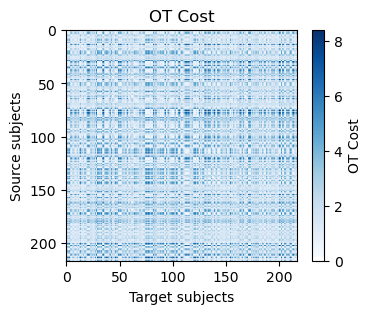

In [80]:
C_dir = np.load(MAIN_DATA_DIR / "cost_matrix_dir.npy")

plt.figure(figsize=(4,3))
im = plt.imshow(C_dir, cmap='Blues', aspect='equal')
cbar = plt.colorbar(im, label='OT Cost')
cbar.set_ticks([0, 2, 4, 6, 8])
plt.title('OT Cost')
plt.xlabel('Target subjects')
plt.ylabel('Source subjects')
plt.show()

## Clustering 

In [81]:
def add_cov_ellipse(ax, x, y, color, alpha=0.18, lw=1.2):
    '''
    Add a 95% covariance ellipse and centroid to a 2D scatter plot.
    '''
    x = np.asarray(x, float)
    y = np.asarray(y, float)

    if x.size < 3:
        return

    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]

    r2 = chi2.ppf(0.95, df=2)
    w, h = 2 * np.sqrt(np.maximum(vals, 0) * r2)
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    center = (x.mean(), y.mean())

    ax.add_patch(Ellipse(center, width=w, height=h, angle=angle, facecolor=color, edgecolor=color, alpha=alpha, lw=lw))
    ax.scatter(*center, s=80, marker="*", color=color, edgecolors="black", linewidths=0.6, zorder=5)

In [84]:
# MS clustering based on OT cost
C_full = np.load(MAIN_DATA_DIR / "cost_matrix_dir.npy")

# Symemtrize cost matrix (mean cost from each pair of subjects)
C_sym = 0.5 * (C_full + C_full.T)
np.fill_diagonal(C_sym, 0.0)  # ensure diagonal is zero

groups = df_sel.loc[subjects, "group"].astype(str).str.upper().to_numpy()
ms_mask = groups == "MS"
ms_idx = np.where(ms_mask)[0]
subjects_ms = np.asarray(subjects)[ms_mask]

C_ms = C_sym[np.ix_(ms_idx, ms_idx)]

# Select number of clusters by silhouette
k_range = range(2, 5)
linkage = "average"

rows = []
best = {"k": None, "sil": -np.inf, "labels": None}

for k in k_range:
    model = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage=linkage)
    labels = model.fit_predict(C_ms).astype(int)
    sil = silhouette_score(C_ms, labels, metric="precomputed")

    rows.append({"k": k, "silhouette": sil})

    if sil > best["sil"]:
        best.update({"k": k, "sil": sil, "labels": labels})

df_k = pd.DataFrame(rows).sort_values("k").reset_index(drop=True)
display(df_k)

# Save clusters silhouette
df_k.to_csv(MAIN_DATA_DIR / "clusters_silhouette.csv", index=False)

best_k = best["k"]
labels_ms = best["labels"]

,k,silhouette
0,2,0.583456
1,3,0.461548
2,4,0.429802


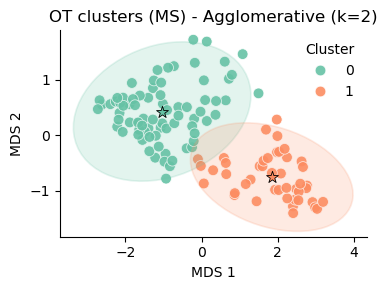

In [90]:
# Embedding MDS
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=41, n_init=10, max_iter=300)
emb = mds.fit_transform(C_ms)

# MS dataframe with cluster labels and MDS embedding
ms_df = df_sel.loc[subjects_ms].copy().reset_index()
ms_df["OT_cluster"] = labels_ms.astype(int)
ms_df["OT_dim1"] = emb[:, 0]
ms_df["OT_dim2"] = emb[:, 1]
plt.figure(figsize=(4, 3))
ax = plt.gca()

# Save cluster assignment
df_ot_clusters = ms_df[["participant_id", "OT_cluster", "OT_dim1", "OT_dim2"]].copy()
df_ot_clusters.to_csv(MAIN_DATA_DIR / "clusters_assignment.csv", index=False)

# Plot OT clusters 
cluster_levels = sorted(ms_df["OT_cluster"].unique())
palette = dict(zip(cluster_levels, sns.color_palette("Set2", n_colors=len(cluster_levels))))

sns.scatterplot(data=ms_df, x="OT_dim1", y="OT_dim2", hue="OT_cluster", hue_order=cluster_levels,
                palette=palette, edgecolor="white", linewidth=0.6, s=60, alpha=0.9, ax=ax)

for lab in cluster_levels:
    d = ms_df.query("OT_cluster == @lab")
    add_cov_ellipse(ax, d["OT_dim1"].to_numpy(), d["OT_dim2"].to_numpy(), color=palette[lab])

ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")
ax.set_title(f"OT clusters (MS) - Agglomerative (k={best_k})")
ax.legend(frameon=False, title="Cluster", fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [91]:
def rank_biserial(x1, x2):
    '''
    Compute rank-biserial correlation for two independent groups.
    '''
    U, _ = stats.mannwhitneyu(x1, x2, alternative="two-sided")
    return 2 * U / (len(x1) * len(x2)) - 1


def hedges_g(x1, x2):
    '''
    Compute Hedges' g for two independent groups.
    '''
    n1, n2 = len(x1), len(x2)
    if n1 < 2 or n2 < 2:
        return np.nan

    v1, v2 = np.var(x1, ddof=1), np.var(x2, ddof=1)
    dof = n1 + n2 - 2
    if dof <= 0:
        return np.nan

    sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / dof
    if sp2 <= 0:
        return np.nan

    d = (np.mean(x1) - np.mean(x2)) / np.sqrt(sp2)
    J = 1 - 3 / (4 * dof - 1)
    return d * J
    
def compare_ot_cluster_clinical(ms_df, cluster_col="OT_cluster", test_mode="ttest"):
    '''
    Compare clinical outcomes between the two OT-derived MS clusters (no covariate adjustment).
    '''
    # ttest (primary): Welch for continuous outcomes, Mann-Whitney sensitivity. 
    # Mannwhitney: Mann-whitney on all outcomes for sensitivity (almost same results)
    if test_mode not in {"ttest", "mannwhitney"}:  
        raise ValueError("test_mode must be 'ttest' or 'mannwhitney'")

    df = ms_df.copy()

    for col in ["EDSS", "SDMT", "BPF", "lesion_load"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    if (df["lesion_load"].dropna() < 0).any():
        raise ValueError("lesion_load contains negative values")

    df["lesion_load_log1p"] = np.log1p(df["lesion_load"])

    specs = [
        ("EDSS", "EDSS", "ordinal/raw"),
        ("SDMT", "SDMT", "raw"),
        ("BPF", "BPF", "raw"),
        ("lesion_load", "lesion_load_log1p", "log1p(lesion_load)")
    ]

    rows = []

    for variable, column, scale in specs:
        use_welch = test_mode == "ttest" and variable != "EDSS"

        if use_welch:
            x0 = df.loc[df[cluster_col] == 0, column].dropna().to_numpy(float)
            x1 = df.loc[df[cluster_col] == 1, column].dropna().to_numpy(float)
            res = stats.ttest_ind(x0, x1, equal_var=False, alternative="two-sided")
            test, stat_name = "Welch t-test", "t"
            effect, effect_name = hedges_g(x0, x1), "Hedges' g"

        else:
            x0 = df.loc[df[cluster_col] == 0, variable].dropna().to_numpy(float)
            x1 = df.loc[df[cluster_col] == 1, variable].dropna().to_numpy(float)
            res = stats.mannwhitneyu(x0, x1, alternative="two-sided")
            test, stat_name = "Mann-Whitney U", "U"
            effect, effect_name = rank_biserial(x0, x1), "Rank-biserial r"
            scale = "ordinal/raw" if variable == "EDSS" else "raw"

        rows.append({"variable": variable, "analysis_scale": scale, "test": test, "contrast": "0 vs 1",
                     "stat_name": stat_name, "stat": float(res.statistic), "effect": float(effect),
                     "effect_size": effect_name, "p_raw": float(res.pvalue)})

    results = pd.DataFrame(rows)
    results["p_fdr_bh"] = multipletests(results["p_raw"], method="fdr_bh")[1]

    return results


def fit_ols_hc3(df, y, var, covs):
    '''
    Fit an OLS model with HC3 robust standard errors.
    '''
    d = df[[y, "cluster_bin"] + covs].dropna().copy()
    terms = ["cluster_bin"] + [
        f"C({c})" if isinstance(d[c].dtype, pd.CategoricalDtype) or d[c].dtype == object else c
        for c in covs
    ]

    res = smf.ols(y + " ~ " + " + ".join(terms), data=d).fit(cov_type="HC3", use_t=True)

    beta = res.params["cluster_bin"]
    ci_low, ci_high = res.conf_int().loc["cluster_bin"]
    sd_y = d[y].std(ddof=1)

    return {
        "variable": var,
        "outcome_used": y,
        "model": "OLS_HC3",
        "n": int(res.nobs),
        "effect": beta,
        "effect_name": "Adjusted mean difference",
        "std_effect": beta / sd_y,
        "CI_low": ci_low,
        "CI_high": ci_high,
        "stat_name": "t",
        "stat": res.tvalues["cluster_bin"],
        "p": res.pvalues["cluster_bin"]
    }


def fit_ordered_logit(df, y, var, covs):
    '''
    Fit a proportional-odds ordinal logistic regression model.
    '''
    d = df[[y, "cluster_bin"] + covs].dropna().copy()
    y_levels = np.sort(d[y].unique())
    y_ord = pd.Categorical(d[y], categories=y_levels, ordered=True)

    X = pd.get_dummies(d[["cluster_bin"] + covs], drop_first=True, dtype=float)
    X = X.loc[:, (X.std(axis=0) > 0) | (X.columns == "cluster_bin")]

    res = OrderedModel(y_ord, X, distr="logit").fit(method="bfgs", disp=False, maxiter=1000)

    beta = res.params["cluster_bin"]
    ci_low, ci_high = res.conf_int().loc["cluster_bin"]

    return {
        "variable": var,
        "outcome_used": y,
        "model": "OrderedLogit",
        "n": len(d),
        "effect": np.exp(beta),
        "effect_name": "Odds ratio",
        "std_effect": np.nan,
        "CI_low": np.exp(ci_low),
        "CI_high": np.exp(ci_high),
        "stat_name": "z",
        "stat": beta / res.bse["cluster_bin"],
        "p": res.pvalues["cluster_bin"]
    }
    
def adjust_ot_cluster_clinical(ms_df, cluster_col="OT_cluster", adjusted_covariates=None):
    '''
    Compare clinical outcomes between OT-derived MS clusters after covariate adjustment.
    '''
    df = ms_df.copy()

    for col in ["EDSS", "SDMT", "BPF", "lesion_load", "age", "education"]:
        df[col] = pd.to_numeric(df[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

    if (df["lesion_load"].dropna() < 0).any():
        raise ValueError("lesion_load contains negative values")

    # Cluster 0 vs cluster 1
    df["cluster_bin"] = (df[cluster_col] == 0).astype(int)

    df["lesion_load_log1p"] = np.log1p(df["lesion_load"])
    df["age_z"] = (df["age"] - df["age"].mean()) / df["age"].std()
    df["education_z"] = (df["education"] - df["education"].mean()) / df["education"].std()
    df["sex"] = df["sex"].astype("category")

    if adjusted_covariates is None:
        adjusted_covariates = {
            "EDSS": ["age", "sex"],
            "BPF": ["age", "sex"],
            "lesion_load": ["age", "sex"],
            "SDMT": ["age", "sex", "education"]
        }

    covariate_map = {"age": "age_z", "sex": "sex", "education": "education_z"}
    outcome_map = {
        "EDSS": "EDSS",
        "BPF": "BPF",
        "lesion_load": "lesion_load_log1p",
        "SDMT": "SDMT"
    }

    rows = []

    for variable, outcome in outcome_map.items():
        covariates = adjusted_covariates[variable]
        covs = [covariate_map[c] for c in covariates]

        if variable == "EDSS":
            row = fit_ordered_logit(df, outcome, variable, covs)
        else:
            row = fit_ols_hc3(df, outcome, variable, covs)

        row["covariates"] = " + ".join(covariates)
        row["contrast"] = "0 vs 1"
        rows.append(row)

    results = pd.DataFrame(rows)
    results["p_fdr_bh"] = multipletests(results["p"], method="fdr_bh")[1]
    results = results.rename(columns={"p": "p_raw"})

    return results[
        ["variable", "model", "covariates", "contrast", "effect", "std_effect",
         "CI_low", "CI_high", "stat_name", "stat", "p_raw", "p_fdr_bh"]
    ]

def plot_ot_cluster_clinical(ms_df, clinical_results, cluster_col="OT_cluster", alpha=0.05):
    '''
    Plot min-max normalized clinical variables across OT-derived MS clusters.
    '''
    features = ["EDSS", "SDMT", "BPF", "lesion_load"]
    labels = {"EDSS": "EDSS", "SDMT": "SDMT", "BPF": "BPF", "lesion_load": "Lesion Load"}
    cluster_levels = sorted(ms_df[cluster_col].dropna().unique())

    if len(cluster_levels) != 2:
        raise ValueError(f"Expected two clusters, found {cluster_levels}")

    rows = []

    for feature in features:
        d = ms_df[[cluster_col, feature]].copy()
        d[feature] = pd.to_numeric(d[feature], errors="coerce")
        d = d.dropna()

        vmin, vmax = d[feature].min(), d[feature].max()
        d["Score"] = 0.0 if vmax == vmin else (d[feature] - vmin) / (vmax - vmin)
        d["Feature"] = labels[feature]
        rows.append(d[[cluster_col, "Feature", "Score"]])

    df_plot = pd.concat(rows, ignore_index=True)

    p_lookup = clinical_results.set_index("variable")["p_fdr_bh"].to_dict()
    pairs = [((labels[f], cluster_levels[0]), (labels[f], cluster_levels[1]))
             for f in features if p_lookup[f] < alpha]
    pvals = [p_lookup[f] for f in features if p_lookup[f] < alpha]

    fig, ax = plt.subplots(figsize=(7, 2.5), constrained_layout=True)

    sns.boxplot(data=df_plot, x="Feature", y="Score", hue=cluster_col,
                order=[labels[f] for f in features], hue_order=cluster_levels,
                palette="Set2", showfliers=False, ax=ax)

    if pairs:
        annot = Annotator(ax, pairs=pairs, data=df_plot, x="Feature", y="Score", hue=cluster_col,
                          order=[labels[f] for f in features], hue_order=cluster_levels)
        annot.configure(test=None, text_format="star", loc="inside", verbose=False)
        annot.set_pvalues(pvals)
        annot.annotate()

    ax.set_xlabel("")
    ax.set_ylabel("Normalized score")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    handles, legend_labels = ax.get_legend_handles_labels()
    ax.legend(handles[:len(cluster_levels)], legend_labels[:len(cluster_levels)],
              title="Cluster", frameon=False, loc="upper center",
              bbox_to_anchor=(0.5, 1.28), ncol=len(cluster_levels))

    return fig, ax
    

In [94]:
df_ot_clinical = compare_ot_cluster_clinical(ms_df, test_mode="ttest")
print('Unadjusted comparison:')
display(df_ot_clinical)

adjusted_covariates = {
    "EDSS": ["age", "sex"],
    "BPF": ["age", "sex"],
    "lesion_load": ["age", "sex"],
    "SDMT": ["age", "sex", "education"]
}

df_ot_clinical_adjusted = adjust_ot_cluster_clinical(ms_df, adjusted_covariates=adjusted_covariates)
print('Covariate-adjusted clinical models:')
display(df_ot_clinical_adjusted)

df_ot_clinical.to_csv(MAIN_DATA_DIR / "clusters_comparison.csv", index=False)
df_ot_clinical_adjusted.to_csv(MAIN_DATA_DIR / "clusters_comparison_adjusted.csv", index=False)

Unadjusted comparison:


,variable,analysis_scale,test,contrast,stat_name,stat,effect,effect_size,p_raw,p_fdr_bh
0,EDSS,ordinal/raw,Mann-Whitney U,0 vs 1,U,2118.000000,0.234266,Rank-biserial r,0.029499,0.039332
1,SDMT,raw,Welch t-test,0 vs 1,t,-1.317870,-0.245161,Hedges' g,0.190846,0.190846
2,BPF,raw,Welch t-test,0 vs 1,t,-2.593683,-0.474285,Hedges' g,0.010982,0.021964
3,lesion_load,log1p(lesion_load),Welch t-test,0 vs 1,t,2.674967,0.539541,Hedges' g,0.009252,0.021964


Covariate-adjusted clinical models:


,variable,model,covariates,contrast,effect,std_effect,CI_low,CI_high,stat_name,stat,p_raw,p_fdr_bh
0,EDSS,OrderedLogit,age + sex,0 vs 1,2.107885,NaN,1.072624,4.142343,z,2.163360,0.030514,0.040685
1,BPF,OLS_HC3,age + sex,0 vs 1,-0.013992,-0.382396,-0.025791,-0.002192,t,-2.348225,0.020527,0.040685
2,lesion_load,OLS_HC3,age + sex,0 vs 1,0.750783,0.496546,0.166838,1.334727,t,2.546053,0.012183,0.040685
3,SDMT,OLS_HC3,age + sex + education,0 vs 1,-1.961117,-0.137326,-6.938529,3.016295,t,-0.780303,0.436788,0.436788


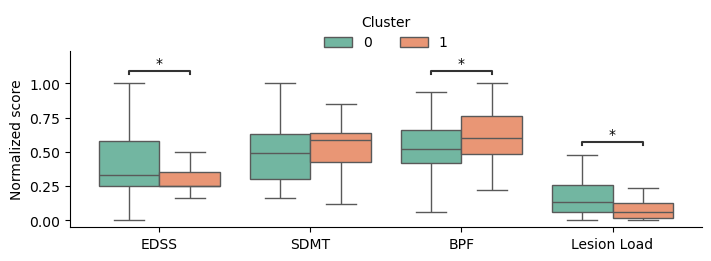

In [95]:
fig, ax = plot_ot_cluster_clinical(ms_df, df_ot_clinical)
plt.show()